In [ ]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("../figures", exist_ok=True)

titanic = pd.read_csv("../data/titanic_propre.csv")
taxis = sns.load_dataset("taxis")
taxis["pickup"] = pd.to_datetime(taxis["pickup"])

714 âges connus, 56 % entre 20 et 40 ans, médiane 28.0


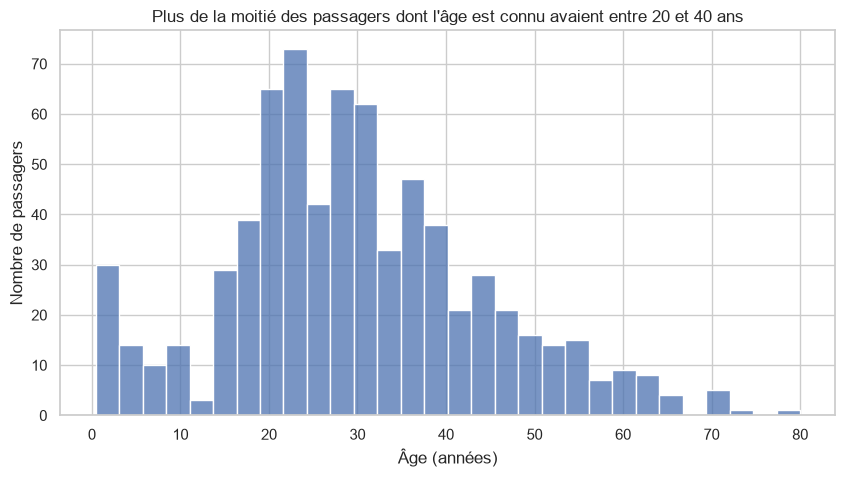

In [ ]:
# On garde les âges connus : les âges remplacés à l'exercice 08 créeraient des pics artificiels
ages_connus = sns.load_dataset("titanic")["age"].dropna()
print(len(ages_connus), "âges connus, médiane", ages_connus.median())
entre_20_40 = ages_connus[(ages_connus >= 20) & (ages_connus <= 40)]
print(f"{len(entre_20_40) / len(ages_connus) * 100:.0f} % entre 20 et 40 ans")

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(x=ages_connus, bins=30, ax=ax)
ax.set_title("Plus de la moitié des passagers dont l'âge est connu avaient entre 20 et 40 ans")
ax.set_xlabel("Âge (années)")
ax.set_ylabel("Nombre de passagers")
fig.savefig("../figures/ages.png", dpi=150, bbox_inches="tight")
plt.show()

**Type choisi :** histogramme, car on veut la distribution d'une seule variable quantitative.

**Conclusion :** parmi les 714 passagers dont l'âge est connu, 56 % avaient entre 20 et 40 ans et l'âge médian est de 28 ans. Il y a peu d'enfants et très peu de passagers de plus de 60 ans.

**Type choisi :** histogramme, car on veut la distribution d'une seule variable quantitative.

**Conclusion :** parmi les 714 passagers dont l'âge est connu, 56 % avaient entre 20 et 40 ans et l'âge médian est de 28 ans. Il y a aussi un petit groupe de jeunes enfants (moins de 5 ans) et très peu de passagers de plus de 60 ans.

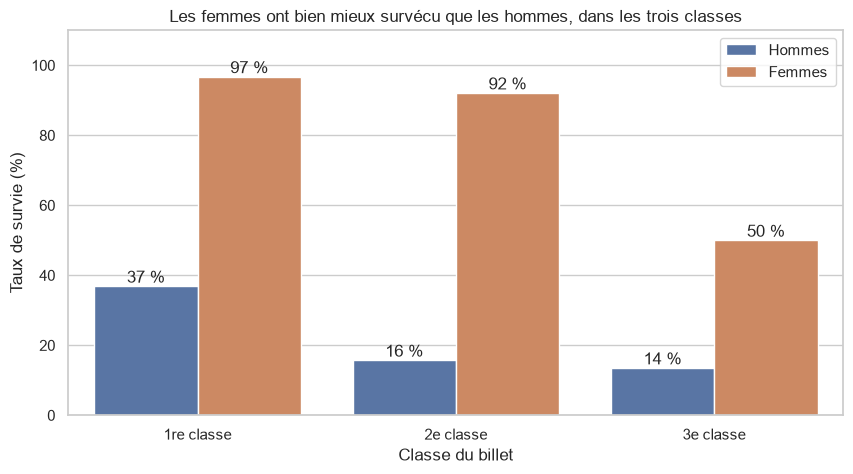

In [ ]:
survie = titanic.groupby(["pclass", "sex"])["survived"].mean() * 100
survie = survie.round(0).reset_index()
print(survie)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=survie, x="pclass", y="survived", hue="sex", ax=ax)
ax.set_ylim(0, 100)
ax.set_title("Les femmes ont bien mieux survécu que les hommes, dans les trois classes")
ax.set_xlabel("Classe du billet")
ax.set_ylabel("Taux de survie (%)")
fig.savefig("../figures/survie_classe_sexe.png", dpi=150, bbox_inches="tight")
plt.show()

**Type choisi :** barres groupées, car on compare une mesure (le taux de survie) entre catégories. La couleur distingue les femmes (female) des hommes (male). L'axe part de 0.

**Conclusion :** en 1re classe, 97 % des femmes ont survécu contre 37 % des hommes. En 2e classe, 92 % contre 16 %. En 3e classe, 50 % contre 14 %. L'écart est énorme dans chaque classe.

{'1re classe': 58.7, '2e classe': 14.2, '3e classe': 8.0}


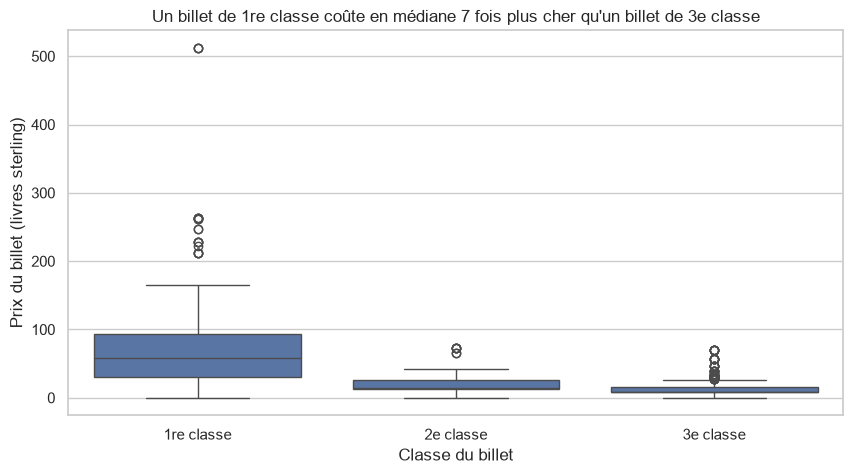

In [ ]:
print(titanic.groupby("pclass")["fare"].median().round(1))

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=titanic, x="pclass", y="fare", ax=ax)
ax.set_title("Un billet de 1re classe coûte en médiane 7 fois plus cher qu'un billet de 3e classe")
ax.set_xlabel("Classe du billet")
ax.set_ylabel("Prix du billet (livres sterling)")
fig.savefig("../figures/prix_par_classe.png", dpi=150, bbox_inches="tight")
plt.show()

**Type choisi :** boîte à moustaches, car on compare la distribution d'une variable quantitative entre catégories, et on veut voir les valeurs extrêmes.

**Conclusion :** le prix médian est de 58,7 en 1re classe, 14,2 en 2e et 8,0 en 3e, soit environ 7 fois plus en 1re qu'en 3e. Les prix de 1re classe sont aussi beaucoup plus dispersés, avec des billets allant jusqu'à 512.

Semaine : 4066, week-end : 3372


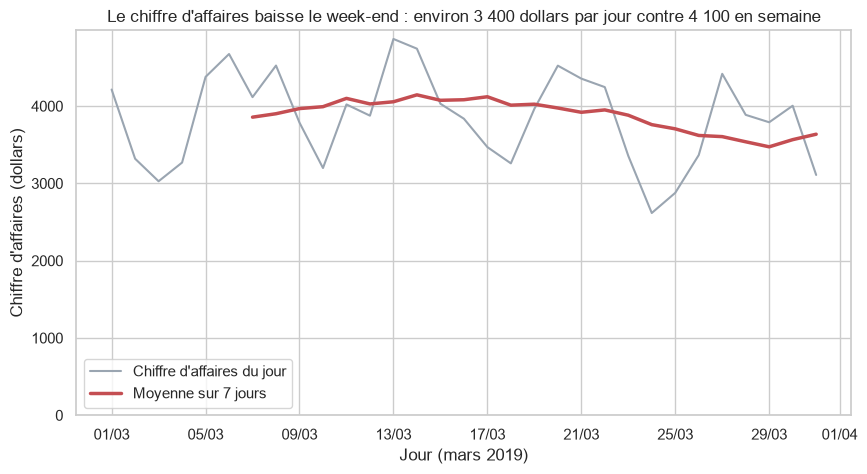

In [ ]:
ca_par_jour = taxis.set_index("pickup").resample("D")["total"].sum()
ca_par_jour = ca_par_jour.iloc[1:]  # le 28 février n'a qu'une seule course

est_week_end = ca_par_jour.index.dayofweek >= 5
print("Semaine :", round(ca_par_jour[~est_week_end].mean()), "/ week-end :", round(ca_par_jour[est_week_end].mean()))
print("Min :", ca_par_jour.idxmin().date(), round(ca_par_jour.min()))
print("Max :", ca_par_jour.idxmax().date(), round(ca_par_jour.max()))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ca_par_jour.index, ca_par_jour.values)
ax.set_ylim(0)
ax.tick_params(axis="x", rotation=45)
ax.set_title("Le chiffre d'affaires baisse le week-end : environ 3 400 dollars par jour contre 4 100 en semaine")
ax.set_xlabel("Jour (mars 2019)")
ax.set_ylabel("Chiffre d'affaires (dollars)")
fig.savefig("../figures/ca_par_jour.png", dpi=150, bbox_inches="tight")
plt.show()

**Type choisi :** courbe, car on montre une évolution dans le temps.

**Conclusion :** le chiffre d'affaires moyen est de 4 066 dollars par jour en semaine contre 3 372 le week-end. Le jour le plus faible est le dimanche 24 mars (2 617 dollars) et le plus élevé le mercredi 13 mars (4 868 dollars). Le 28 février a été écarté : une seule course.

51 courses à distance nulle écartées
Pente : 2.80, ordonnée : 4.49, corrélation : 0.952


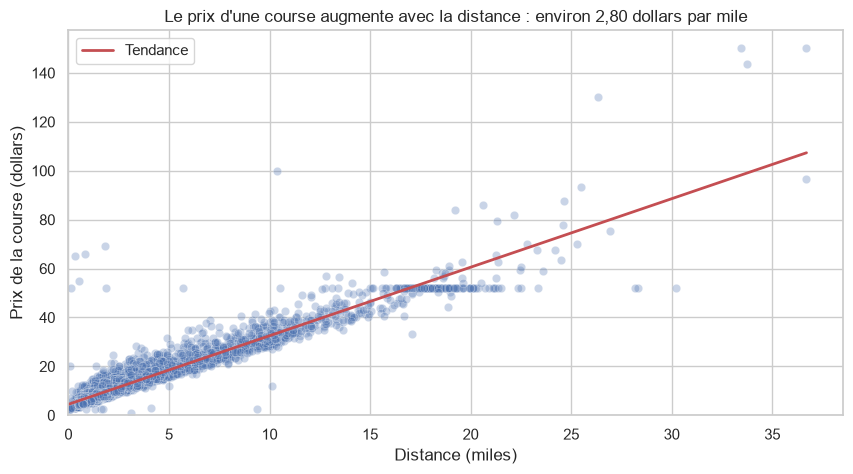

In [ ]:
print("Corrélation :", round(taxis["distance"].corr(taxis["fare"]), 2))

fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=taxis, x="distance", y="fare", alpha=0.3, ax=ax)
ax.set_title("Plus la course est longue, plus elle est chère")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Prix de la course (dollars)")
fig.savefig("../figures/distance_prix.png", dpi=150, bbox_inches="tight")
plt.show()

**Type choisi :** nuage de points, car on étudie le lien entre deux variables quantitatives. La transparence évite que les points s'empilent.

**Conclusion :** le lien est très fort (corrélation de 0,92) : plus la distance augmente, plus le prix augmente. On voit aussi un palier de prix pour les longues distances, probablement un tarif forfaitaire.